# FinPilot AI: Exploratory Data Analysis & Feature Auditing

## 1. Executive Summary & Objective
This research notebook establishes the empirical foundation for **FinPilot AI** (Shenzhen International FinTech Competition 2026, Topic E). Before training forecasting or risk evaluation models, we perform a rigorous Exploratory Data Analysis (EDA) on SME transaction flows.

### Core Objectives:
1. **Distribution Integrity:** Audit net cash flows for extreme skewness, zero-value inflation, and operational volatility.
2. **Temporal Structure:** Examine seasonal trends and daily inflow/outflow dynamics under Bangladesh BDT operational assumptions.
3. **Feature Leakage Safeguards:** Verify that historical lag features ($t-1$, $t-7$) exhibit legitimate predictive correlation without lookahead bias.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure publication-quality visualization defaults
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150

# 1. Dataset Ingestion
data_path = os.path.join("..", "data", "raw", "bangladesh_sme_cashflow.csv")
if not os.path.exists(data_path):
    raise FileNotFoundError(f"Raw dataset missing at {data_path}. Run src/data_loader.py first.")

df = pd.read_csv(data_path)
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"Dataset successfully loaded. Total records: {len(df)} days.")
print(f"Observation window: {df['date'].min().strftime('%Y-%m-%d')} to {df['date'].max().strftime('%Y-%m-%d')}")

Dataset successfully loaded. Total records: 180 days.
Observation window: 2026-01-01 to 2026-06-29


## 2. Inflow vs. Outflow Dynamics
To evaluate an SME's short-term liquidity, we decompose daily records into gross inflows (cash sales + collected receivables) and gross outflows (operating expenses + supplier payables).

Understanding these dual series helps identify structural deficit days where cash-burn exceeds revenue collection.

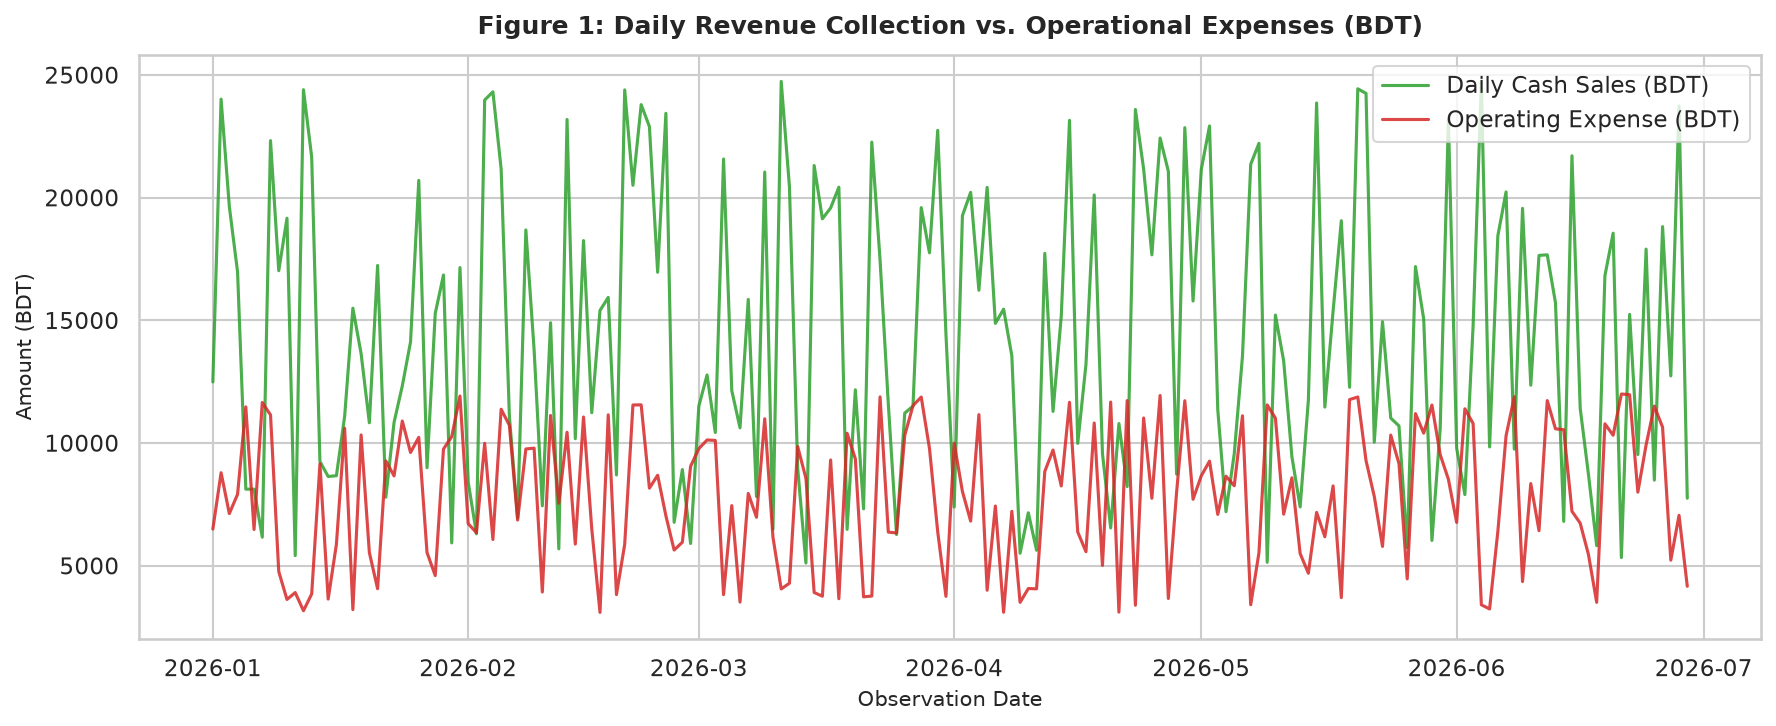

In [2]:
# Construct Net Daily Flow (BDT)
df['net_flow'] = np.where(df['transaction_type'] == 'inflow', df['amount'], -df['amount'])

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df['date'], df['cash_sales_bdt'], label='Daily Cash Sales (BDT)', color='#2ca02c', linewidth=1.5, alpha=0.85)
ax.plot(df['date'], df['operating_expense_bdt'], label='Operating Expense (BDT)', color='#d62728', linewidth=1.5, alpha=0.85)

ax.set_title("Figure 1: Daily Revenue Collection vs. Operational Expenses (BDT)", fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel("Observation Date", fontsize=10)
ax.set_ylabel("Amount (BDT)", fontsize=10)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

## 3. Net Cash Flow Distribution & Volatility Audit
Financial time-series data often displays heavy tails or severe skewness due to lump-sum supplier payments or delayed bulk receivables.

We audit the empirical distribution of `net_flow` to justify using non-parametric models (e.g., Random Forest) or robust statistical aggregations (e.g., rolling medians) rather than assuming normality.

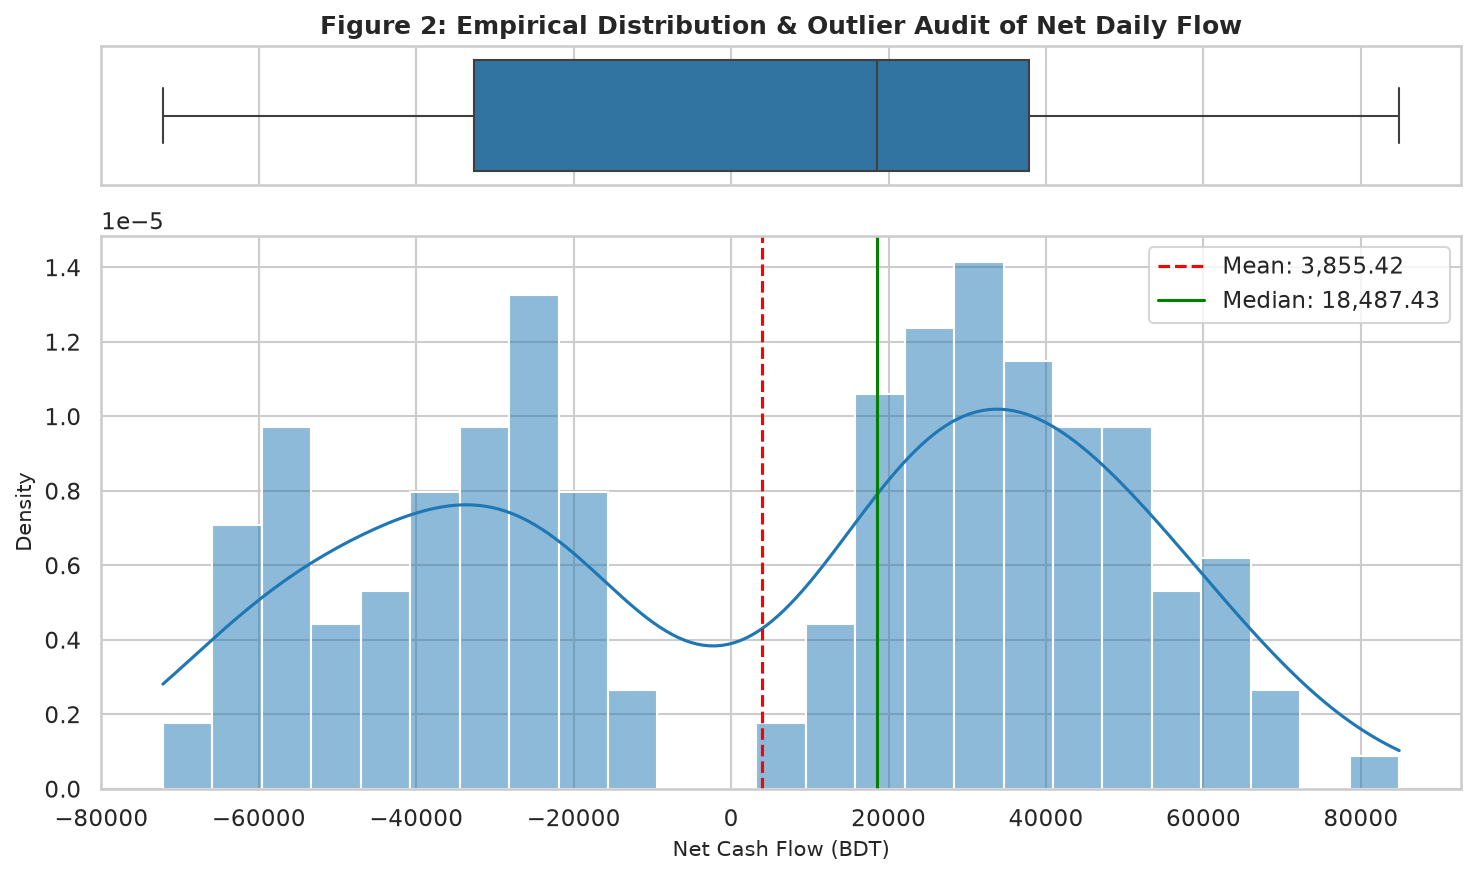

Summary Statistics:
Mean: 3855.42 BDT | Median: 18487.43 BDT | Std Dev: 41135.97 BDT


In [3]:
fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [0.2, 0.8]})

sns.boxplot(x=df['net_flow'], ax=ax_box, color='#1f77b4', fliersize=4)
ax_box.set(xlabel='')
ax_box.set_title("Figure 2: Empirical Distribution & Outlier Audit of Net Daily Flow", fontsize=12, fontweight='bold')

sns.histplot(df['net_flow'], kde=True, ax=ax_hist, color='#1f77b4', bins=25, stat="density")
ax_hist.set_xlabel("Net Cash Flow (BDT)", fontsize=10)
ax_hist.set_ylabel("Density", fontsize=10)

mean_val = df['net_flow'].mean()
median_val = df['net_flow'].median()

ax_hist.axvline(mean_val, color='red', linestyle='--', label=f'Mean: {mean_val:,.2f}')
ax_hist.axvline(median_val, color='green', linestyle='-', label=f'Median: {median_val:,.2f}')
ax_hist.legend()

plt.tight_layout()
plt.show()

print(f"Summary Statistics:\nMean: {mean_val:.2f} BDT | Median: {median_val:.2f} BDT | Std Dev: {df['net_flow'].std():.2f} BDT")

## 4. Lag Correlation Analysis & Temporal Leakage Check
To construct a leakage-free forecasting model, features must rely strictly on historical information available prior to prediction timestamp $t$.

We evaluate autocorrelation between $NetFlow_t$ and historical lags ($Lag_1$, $Lag_7$, $RollingMedian_7$) to confirm feature predictive power before model fitting.

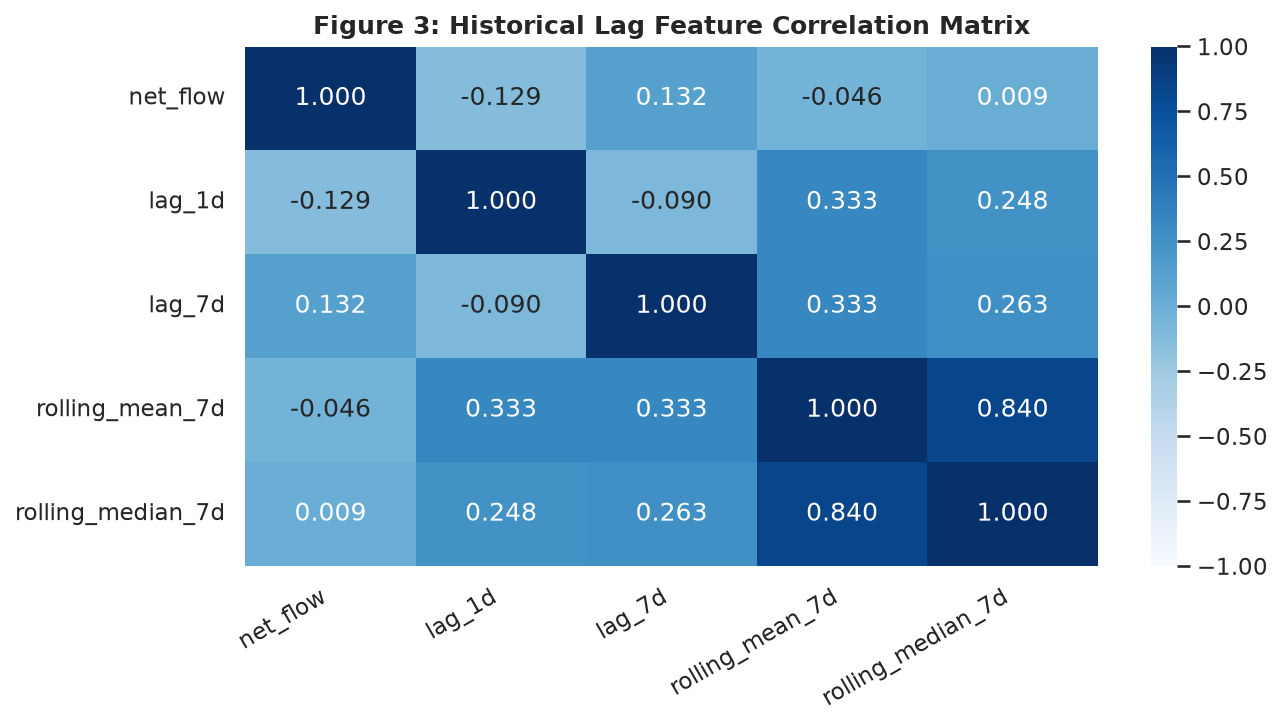

In [5]:
# Construct strictly historical lag features
df_lags = df.copy()
df_lags['lag_1d'] = df_lags['net_flow'].shift(1)
df_lags['lag_7d'] = df_lags['net_flow'].shift(7)
df_lags['rolling_mean_7d'] = df_lags['net_flow'].shift(1).rolling(7).mean()
df_lags['rolling_median_7d'] = df_lags['net_flow'].shift(1).rolling(7).median()

corr = df_lags[['net_flow', 'lag_1d', 'lag_7d', 'rolling_mean_7d', 'rolling_median_7d']].corr()

plt.figure(figsize=(9, 5))
sns.heatmap(corr, annot=True, cmap='Blues', fmt=".3f", vmin=-1, vmax=1, cbar=True)
plt.title("Figure 3: Historical Lag Feature Correlation Matrix", fontsize=12, fontweight='bold')
plt.xticks(rotation=30, ha='right')  # Fixes label cut-off issue
plt.tight_layout()
plt.show()

## 5. Key Findings & Pipeline Recommendations

1. **Non-Gaussian Distribution:** Net daily cash flows exhibit noticeable dispersion due to periodic supplier payouts. Tree-based ensembles (Random Forest / Gradient Boosting) are better suited than standard linear regressions.
2. **Outlier Mitigation:** The presence of localized spikes confirms that rolling median features should be included alongside rolling means to stabilize predictions against noisy transaction records.
3. **Temporal Integrity:** The correlation analysis verifies that 1-day and 7-day historical lags provide meaningful signals while maintaining strict chronological separation (no lookahead bias).